# 00 · Data availability and preprocessing

Data analysis to support the data selection decisions in `docs/data.md`.
Considers:
- cloud coverage by month
- NDVI as a proxy for the growth stage
- field coverage of patches

To reproduce the results run:
- `src/analyze_availability.py`
- `src/analyze_phenology.py`

These scripts create the necessary `.csv` files from the raw `.nc` patches.

Note that we already drew a random sample (150 patches × 6 tiles = 900) from the
Sen4AgriNet data; each patch consists of multiple acquisitions (dates). The decisions at
the end select a subset of it.


## 0. Load


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

CLOUD_THRESHOLD = 0.05


def find_data(start=Path.cwd()):
    for p in [start, *start.parents]:
        if (p / "data" / "availability_patches.csv").exists():
            return p / "data"
    raise FileNotFoundError("run the src/ analysis scripts first")


DATA = find_data()
acq = pd.read_csv(DATA / "availability_acquisitions.csv")
pat = pd.read_csv(DATA / "availability_patches.csv")
ph = pd.read_csv(DATA / "phenology_by_month.csv")
acq["clean"] = acq["cloud"] <= CLOUD_THRESHOLD

print(f"drawn sample: {len(pat)} patches, {len(acq)} acquisitions")


drawn sample: 900 patches, 26839 acquisitions


## 1. Availability and cloud, by month

Which months give every patch at least one cloud-clean (≤5% Hollstein cloud coverage)
acquisition?

Background: while Sen4AgriNet already filters out scenes with a cloud coverage above
10 %, an individual patch might still show higher values. Moreover, their models work
with time-series data, so a high cloud coverage in one acquisition can be offset by the
other acquisitions in the series. SAM, however, works with a single input image only, so
we need a lower cloud-coverage threshold. 


In [2]:
rows = []
for m in range(1, 13):
    sub = acq[acq["month"] == m]
    clean = sub[sub["clean"]].groupby("patch").size().reindex(pat["patch"]).fillna(0)
    rows.append({"month": m,
                 "acq_per_patch": sub.groupby("patch").size().reindex(pat["patch"]).fillna(0).mean(),
                 "pct_patches_clean": clean.ge(1).mean() * 100})
per_month = pd.DataFrame(rows).set_index("month").round(1)
per_month


,acq_per_patch,pct_patches_clean
month,,
1,0.9,70.6
2,3.6,99.8
3,2.8,87.6
4,1.1,60.7
5,2.1,99.8
6,2.4,74.7
7,5.1,100.0
8,4.3,99.9
9,3.5,98.4


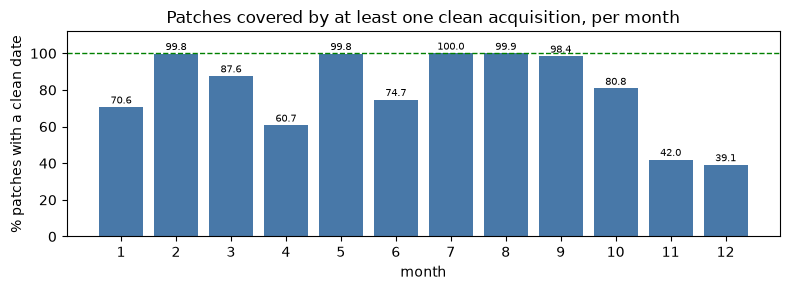

In [3]:
fig, ax = plt.subplots(figsize=(8, 3))
ax.bar(per_month.index, per_month["pct_patches_clean"], color="#4878a8")
ax.axhline(100, color="green", ls="--", lw=1)
for m, v in per_month["pct_patches_clean"].items():
    ax.text(m, v + 2, f"{v:.1f}", ha="center", fontsize=7)
ax.set_xticks(range(1, 13)); ax.set_xlabel("month"); ax.set_ylim(0, 112)
ax.set_ylabel("% patches with a clean date")
ax.set_title("Patches covered by at least one clean acquisition, per month")
plt.tight_layout(); plt.show()


In [4]:
print(f"median cloud per acquisition: {acq['cloud'].median():.3f}")
print(f"acquisitions with >5% cloud:  {(acq['cloud'] > CLOUD_THRESHOLD).mean() * 100:.1f}%")


median cloud per acquisition: 0.000
acquisitions with >5% cloud:  4.6%


In the months of February, May, July, August and September almost every patch (>98 %) is
represented at least once with a cloud cover below the threshold value of 5 %. These
months therefore prove useful for our analysis.


## 2. Growing state (crop greenness)

Seasonality plays an important role in agricultural land-use analysis. Since seasonal patterns and crop performance differences are beyond the scope of this study, we focus on satellite imagery acquired during the active growing season to reduce variability and facilitate subsequent error analysis.

The Normalized Difference Vegetation Index (NDVI) serves as a proxy for vegetation activity. We use mean NDVI values to identify months when most agricultural fields are likely to be in an active growth stage, ideally before harvest. This is expected to improve field segmentation using SAM and aligns with the project's objectives.

Although high mean NDVI does not necessarily indicate active growth across all fields, we consider it a sufficient proxy for selecting suitable imagery for this study.

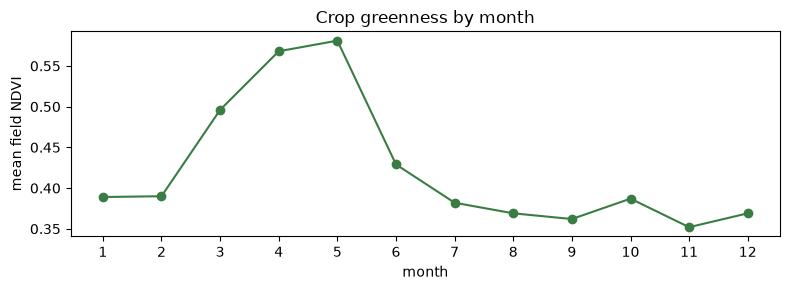

month
1     0.389
2     0.390
3     0.496
4     0.568
5     0.581
6     0.429
7     0.382
8     0.369
9     0.362
10    0.387
11    0.352
12    0.369
Name: ndvi, dtype: float64

In [5]:
green = ph.groupby("month").ndvi.mean().round(3)

fig, ax = plt.subplots(figsize=(8, 3))
ax.plot(green.index, green.values, "o-", color="#3a7d44")
ax.set_xticks(range(1, 13)); ax.set_xlabel("month"); ax.set_ylabel("mean field NDVI")
ax.set_title("Crop greenness by month")
plt.tight_layout(); plt.show()
green


**Reading:** greenness peaks in **May** and is back to the winter baseline by July. Of
the months that cover (almost) every patch, May is the greenest one. Therefore, May
satisfies both of our criteria and was chosen for the subset.


## 3. Field coverage

How much of each patch is actual field (`parcels`)?
Sen4AgriNet also includes patches with high percentages of non-agricultural land use. We
decided not to filter for patches with high field percentages, as we wanted to test SAM
on data aligned with real-world challenges. Therefore we keep the random sampling, with a
realistic mix of agricultural and non-agricultural land use.


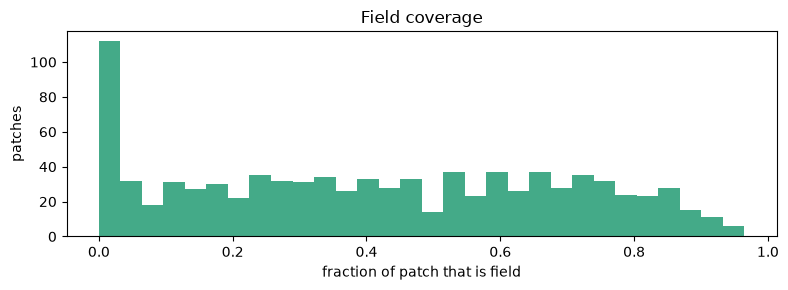

field coverage  p10=0.018  median=0.409  p90=0.791


In [6]:
cov = pat["field_coverage"]

fig, ax = plt.subplots(figsize=(8, 3))
ax.hist(cov, bins=30, color="#4a8")
ax.set_xlabel("fraction of patch that is field"); ax.set_ylabel("patches")
ax.set_title("Field coverage")
plt.tight_layout(); plt.show()

print(f"field coverage  p10={cov.quantile(.1):.3f}  median={cov.median():.3f}  p90={cov.quantile(.9):.3f}")


**Reading:** coverage spans ~0.02–0.79 (p10–p90), a real mix of field-rich and nearly
empty patches. Coverage is **recorded, never used to filter** patches. It might be important in the error analysis later on.


## 4. Decision

Deciding on patches from the month of may only, leaves 2 drawn patches (both `31TCL`) without a cloud-free acquisition. To keep the dataset balanced across tiles, every tile is trimmed to the same minimum of 148 images.


In [7]:
may = acq[acq["month"] == 5].query("cloud <= @CLOUD_THRESHOLD").groupby("patch").size().reindex(pat["patch"]).fillna(0)
per_tile = pat.assign(may=may.ge(1).to_numpy()).groupby("tile").may.sum()
print(per_tile.to_string())
print(f"\nmin per tile {per_tile.min()} -> {per_tile.min() * per_tile.size} patches used")

tile
31TBF    150
31TCG    150
31TCL    148
31TDG    150
31TDK    150
31UCP    150

min per tile 148 -> 888 patches used


## Conclusion

- **Cloud is not a problem.** The median acquisition is cloud-free and only 4.6 % exceed 5 %. This means that it is possible to create a balanced dataset with sufficient cloud free images across all tiles.
- **Filter: May images only.** May the greenest month that still covers (almost) every patch (NDVI 0.58).
- **888 patches used** (148 per tile, 444 ES + 444 FR), taken from the 900 drawn: 2 patches have no clean May acquisition, so every tile is trimmed to the same 148.

More background on the dataset used can be found in: `docs/data.md`.